In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 17.5 — Invariants

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`, p. 387, Examples 17.5.7–17.5.9, equations (17.67)–(17.70). Native DisCoPy drawings run **top to bottom**, preserving left-to-right tensor order. A coupon replaces SMSA's specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.

Take $V=\mathbb C^3$, the defining representation of $\mathfrak{sl}(3)$ in Example 17.5.9. The tensor $\delta=\sum_{i=1}^3 e_i\otimes e^i$ has coefficients $\delta^i_j$. It is the native coevaluation $1\to V\otimes V^*$, with `V.l` representing the ordered dual. We first inspect its entries and then check the Lie action in (17.69).


In [1]:
from discopy import rigid, tensor
V = rigid.Ty('V')
delta = rigid.Cap(V, V.l)
F = tensor.Functor({V: 3}, {}, dom=rigid.Category(), dtype=int)
print('Invariant boundary:', delta.dom, '->', delta.cod)
print('Kronecker entries:')
print(F(delta).array)
print('Expected identity entries:')
print(tensor.Tensor[int].id(tensor.Dim(3)).array)
print('Entries match:', (F(delta).array == tensor.Tensor[int].id(tensor.Dim(3)).array).all())

Invariant boundary: Ty() -> V @ V.l
Kronecker entries:
[[1 0 0]
 [0 1 0]
 [0 0 1]]
Expected identity entries:
[[1 0 0]
 [0 1 0]
 [0 0 1]]
Entries match: True


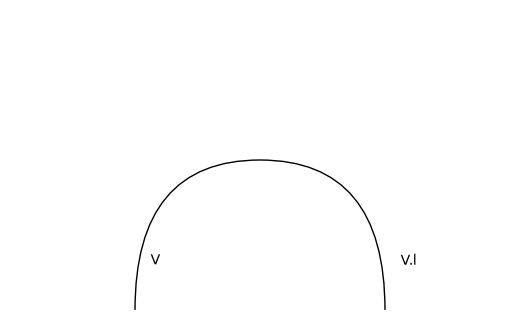

In [2]:
delta.draw(figsize=(5, 3))

For a matrix $M$ acting on column vectors in $V$, the dual action on the dual basis is $-M^{\mathsf T}$. The tensor-product action on $\delta$ is
$$ (M\otimes I)\delta+(I\otimes(-M^{\mathsf T}))\delta. $$
We use eight explicit traceless $3\times3$ matrices: $H_1=\operatorname{diag}(1,-1,0)$, $H_2=\operatorname{diag}(0,1,-1)$, and the six matrix units $E_{ij}$ with $i\ne j$. They form a basis of $\mathfrak{sl}(3)$. Each coupon below is interpreted by its chosen matrix. DisCoPy stores the input index first, so the array assigned to a coupon for $M$ is $M^{\mathsf T}$.


In [3]:
import numpy as np
X = rigid.Box('X', V, V)
X_dual = rigid.Box('dual X', V.l, V.l)
left_action = delta >> (X @ rigid.Id(V.l))
right_action = delta >> (rigid.Id(V) @ X_dual)
matrices = [
    ('H1', np.diag([1, -1, 0])),
    ('H2', np.diag([0, 1, -1])),
    ('E12', np.array([[0, 1, 0], [0, 0, 0], [0, 0, 0]])),
    ('E13', np.array([[0, 0, 1], [0, 0, 0], [0, 0, 0]])),
    ('E21', np.array([[0, 0, 0], [1, 0, 0], [0, 0, 0]])),
    ('E23', np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]])),
    ('E31', np.array([[0, 0, 0], [0, 0, 0], [1, 0, 0]])),
    ('E32', np.array([[0, 0, 0], [0, 0, 0], [0, 1, 0]]))]
for name, M in matrices:
    action = tensor.Functor({V: 3}, {X: M.T, X_dual: -M}, dom=rigid.Category(), dtype=int)
    first = action(left_action).array
    second = action(right_action).array
    total = first + second
    print(name, 'matrix:\n', M)
    print('(M tensor I) delta:\n', first)
    print('(I tensor dual M) delta:\n', second)
    print('Sum, expected zero:\n', total)
    print('Annihilates delta:', np.array_equal(total, np.zeros((3, 3), dtype=int)))


H1 matrix:
 [[ 1  0  0]
 [ 0 -1  0]
 [ 0  0  0]]
(M tensor I) delta:
 [[ 1  0  0]
 [ 0 -1  0]
 [ 0  0  0]]
(I tensor dual M) delta:
 [[-1  0  0]
 [ 0  1  0]
 [ 0  0  0]]
Sum, expected zero:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]
Annihilates delta: True
H2 matrix:
 [[ 0  0  0]
 [ 0  1  0]
 [ 0  0 -1]]
(M tensor I) delta:
 [[ 0  0  0]
 [ 0  1  0]
 [ 0  0 -1]]
(I tensor dual M) delta:
 [[ 0  0  0]
 [ 0 -1  0]
 [ 0  0  1]]
Sum, expected zero:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]
Annihilates delta: True
E12 matrix:
 [[0 1 0]
 [0 0 0]
 [0 0 0]]
(M tensor I) delta:
 [[0 1 0]
 [0 0 0]
 [0 0 0]]
(I tensor dual M) delta:
 [[ 0 -1  0]
 [ 0  0  0]
 [ 0  0  0]]
Sum, expected zero:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]
Annihilates delta: True
E13 matrix:
 [[0 0 1]
 [0 0 0]
 [0 0 0]]
(M tensor I) delta:
 [[0 0 1]
 [0 0 0]
 [0 0 0]]
(I tensor dual M) delta:
 [[ 0  0 -1]
 [ 0  0  0]
 [ 0  0  0]]
Sum, expected zero:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]
Annihilates delta: True
E21 matrix:
 [[0 0 0]
 [1 0 0]
 [0 0 0]]
(M tensor I) delta:
 

Negative control: use +M transpose on the dual for H1.
Sum:
 [[ 2  0  0]
 [ 0 -2  0]
 [ 0  0  0]]
Annihilates delta (expected False): False


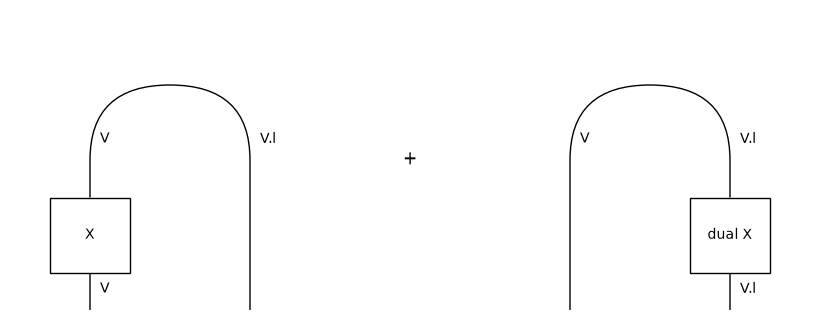

In [4]:
from discopy.drawing import Equation
Equation(left_action, right_action, symbol='+').draw(figsize=(8, 3))
M = matrices[0][1]
wrong_sign = tensor.Functor({V: 3}, {X: M.T, X_dual: M}, dom=rigid.Category(), dtype=int)
wrong_total = wrong_sign(left_action).array + wrong_sign(right_action).array
print('Negative control: use +M transpose on the dual for H1.')
print('Sum:\n', wrong_total)
print('Annihilates delta (expected False):', np.array_equal(wrong_total, np.zeros((3, 3), dtype=int)))


All eight basis actions give the zero tensor with exact integer entries. By linearity this checks invariance under the defining $\mathfrak{sl}(3)$ action. The wrong-sign control gives a nonzero tensor. This is the $N=3$ instance of Example 17.5.9. It does not check the general-$N$ statement or the uniqueness of the invariant. Primitive tensors in (17.73) remain a temporary placeholder.
